In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from behavior_fw.io.load_dataset import load_experiment_dataset
from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition

from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.analysis.calc_velocities import get_velocities
from behavior_fw.visualization.plot_density import (
    plot_dynamic_cartesian_densities,
    plot_dynamic_polar_densities,
)
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)
from behavior_fw.visualization.plot_trajectory import plot_single_fly_trajectory, plot_multi_experiment_split_trajectories

In [3]:
path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 

In [4]:
path_to_metadata = path_dir_dataset / "metadata.csv"
df_metadata = pd.read_csv(path_to_metadata,index_col=0 )
df_metadata

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium,center
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR,300
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR,300
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,95930,2026-08-15 9:59:30,Gr43a,OptoCL,ATR,300
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR,300
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR,300
...,...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR,300
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR,300
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR,300
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR,300


In [ ]:
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="ATR", zone="300")
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)

print(f"Loaded {len(dataset)} flies into memory!")
print("Columns in df_track:", dataset[0]["df_track"].columns.tolist())

In [ ]:
exp = dataset[5]  # Pick first fly

fig, ax = plot_single_fly_trajectory(exp, arena_r=45.0, fps=60.0)
plt.show()

In [ ]:
# Extract reward-centered windows (-2s to +4s)
psth_dict = extract_experiment_psth(
    exp, metrics=["Vf_smooth", "Vr_abs"], window_sec=(-2.0, 4.0)
)

# Plot Trial Heatmap + Average Speed Response
fig, axes = plot_single_experiment_psth(
    psth_dict, metric="Vf_smooth", title=exp["uid"]
)
plt.show()

In [ ]:
fig, axes = plot_condition_psth_summary(
    datasets=[dataset],
    group_names=["Gr43a_ATR"],
    metrics=["Vf_smooth", "Vr_abs"],
    colors=["#F16237"],
    title="PSTH Velocity Summary"
)
plt.show()

In [5]:
df_Gr5a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="ATR", zone="300")
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="300")
df_Gr5a_NR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="NR", zone="300")
df_Gr43a_NR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="300")
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset_Gr5a_ATR_CL = load_experiment_dataset(df_Gr5a_ATR_CL, fps=60.0)
print(f"Loaded {len(dataset_Gr5a_ATR_CL)} flies into memory!")
print("Columns in df_track:", dataset_Gr5a_ATR_CL[0]["df_track"].columns.tolist())

dataset_Gr43a_ATR_CL = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)
dataset_Gr5a_NR_CL = load_experiment_dataset(df_Gr5a_NR_CL, fps=60.0)
dataset_Gr43a_NR_CL = load_experiment_dataset(df_Gr43a_NR_CL, fps=60.0)


Loaded 38 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']


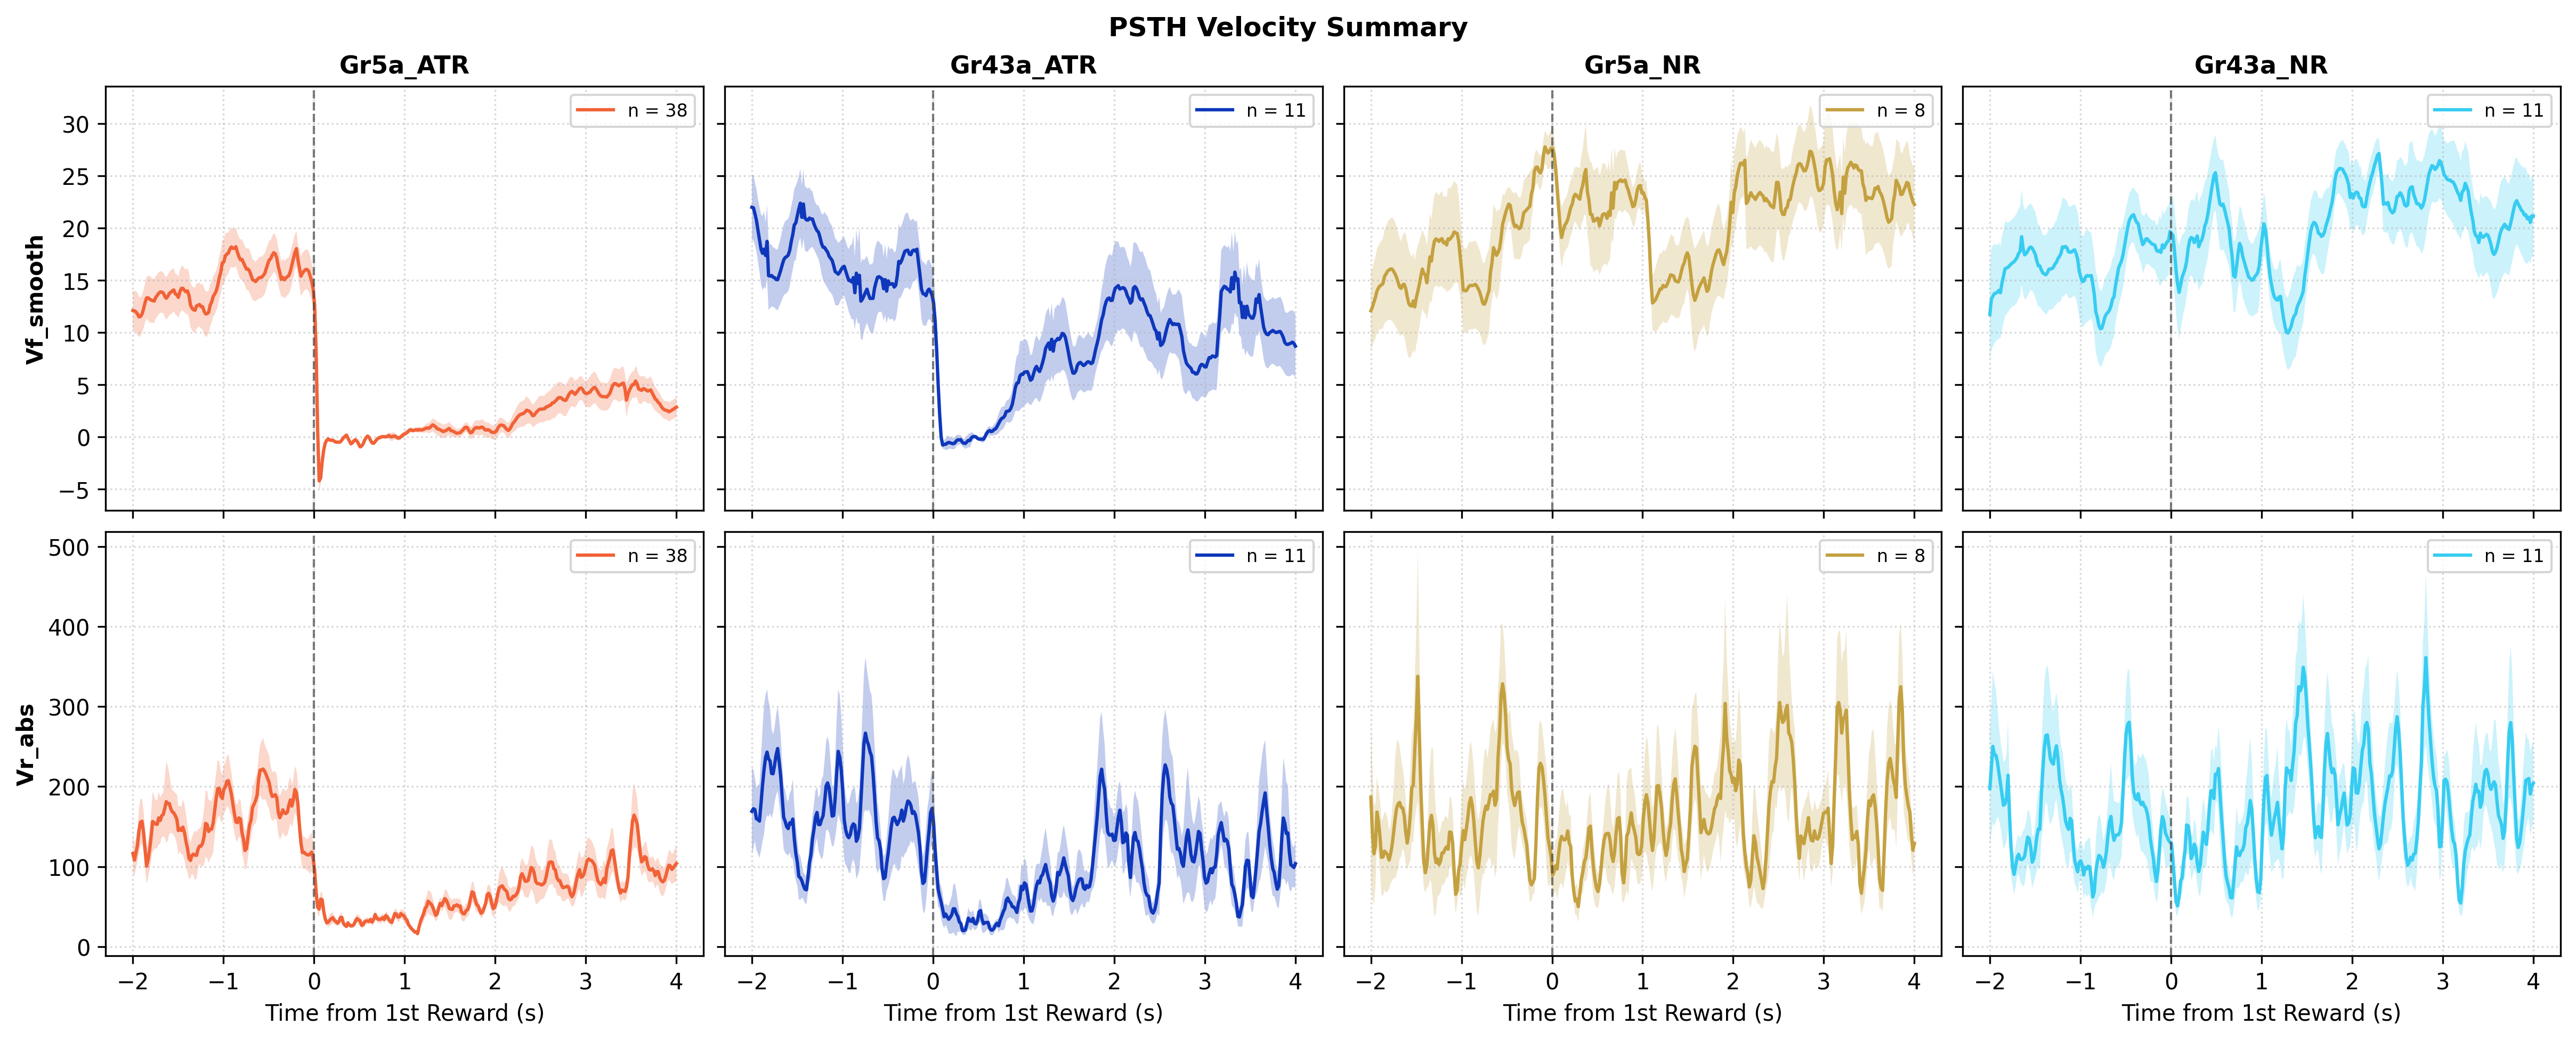

In [6]:

fig, axes = plot_condition_psth_summary(
    datasets=[dataset_Gr5a_ATR_CL,dataset_Gr43a_ATR_CL, dataset_Gr5a_NR_CL, dataset_Gr43a_NR_CL ],
    group_names=["Gr5a_ATR" ,"Gr43a_ATR", "Gr5a_NR", "Gr43a_NR"],
    metrics=["Vf_smooth", "Vr_abs"],
    colors=["#F16237", "#0E37BB", "#C4A140", "#37CCF1"],
    title="PSTH Velocity Summary"
)
plt.show()

In [ ]:
# from behavior_fw.visualization.plot_trajectory import plot_multi_experiment_split_trajectories
# Define your palette map
color_map = {
    "Baseline": "#BA90EB", 
    "Stimulus": "#F16237", 
    "Washout": '#009E73'
}

# Run the plot function across all loaded fly experiments
fig, axes = plot_multi_experiment_split_trajectories(
    dataset=dataset,      
    color_map=color_map,
    arena_r=45.0,
    fps=60.0
)

# fig.savefig("split_trajectories_by_period.svg")

In [ ]:


# 1. Set global experiment parameters
GENOTYPE = "Gr5a"
MEDIUM = "ATR"
PROTOCOL = "OptoCL"

# 2. Filter metadata consistently using these variables
df_selected_meta = select_exp_condition(
    df_metadata, 
    genotype=GENOTYPE, 
    medium=MEDIUM, 
    protocol=PROTOCOL,
    zone = "300"
)

# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset = load_experiment_dataset(df_selected_meta, fps=60.0)

print(f"Loaded {len(dataset)} flies into memory!")
print("Columns in df_track:", dataset[0]["df_track"].columns.tolist())


In [ ]:
# 3. Create global strings for titles and filenames
condition_label = f"{GENOTYPE}_{PROTOCOL}_{MEDIUM}"
fig_title = f"Trajectories: {GENOTYPE} | {PROTOCOL} | {MEDIUM}"

# 4. Color map configuration
color_map = {
    "Baseline": "#BA90EB",
    "Stimulus": "#F16237",
    "Washout": "#009E73"
}

# 5. Generate plot
fig, axes = plot_multi_experiment_split_trajectories(
    dataset=dataset,  # your dataset list corresponding to df_selected_meta
    color_map=color_map,
    fig_title=fig_title,
    arena_r=45.0,
    fps=60.0
)

# # 6. Save using the dynamic condition label
# save_filename = f"trajectories_split_{condition_label}.svg"
# fig.savefig(save_filename, bbox_inches="tight")
# print(f"Saved figure to {save_filename}")